# Классификация ботов по событиям внутри суток

Нужно ранжировать куки по вероятности принадлежности к трафику известных сервисов сбора данных. Единица наблюдения — одна кука с заданным окном; `target=1` обозначает положительный класс разметки.

Итоговое решение — CatBoost на агрегатах событий, временном ритме, разнообразии действий, характеристиках User-Agent и наблюдаемых координатах курсора. На отложенных **17–19 апреля**: **P@R≥0.70 = 0.7308**, baseline — **0.1025**. Полный повторный запуск воспроизвёл эти метрики. Первая отправка на Stepik получила **0.78780**; метки скрытого теста недоступны.

Ноутбук заново читает исходные CSV, строит признаки, повторяет все 27 отдельных конфигураций и четыре ансамбля, проверяет зафиксированное решение и создаёт `submission.csv`. Сохранённые модели и таблицы признаков не нужны. Запускать ячейки по порядку из корня проекта; версии среды указаны в `requirements.txt` и README.
Все ячейки выполнены в новом ядре. В ноутбуке сохранены рассчитанные таблицы и графики; полный запуск занял 8,2 минуты.


In [1]:
import importlib.metadata
import json
import platform
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pandas.testing import assert_frame_equal

from src.features import load_data, build_features, prepare_events
from src.modeling import (
    CAT_DEFAULTS, evaluate, feature_columns, make_model,
    fit_configuration, predict_configuration, validate_submission,
)
from src.diagnostics import (
    best_operating_point, bootstrap_precision, segment_report,
    group_permutation_importance, paired_bootstrap,
)
from bot_detection_challenge.metric import pr_curve, precision_at_recall

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.2})
pd.set_option("display.max_columns", 14)
started = perf_counter()
print("Python:", platform.python_version())


Python: 3.13.14


## 1. Данные и границы доступной информации

Обучение относится к 6–19 апреля, тест — к 20–26 апреля. Случайное разбиение смешало бы прошлое и будущее. Между train и test нет общих `cookie_id`.

Для каждого события проверяется **`window_start_ts <= event_ts < window_end_ts`**. Время конца окна не включается. Возраст куки вычисляется на конец окна. Абсолютную дату и идентификатор куки в модель не передаём.

Разметка отражает известные источники трафика. Она не доказывает, что модель обнаружит любой новый вид автоматизации или что все отрицательные примеры безошибочно размечены.

In [2]:
train, test, events = load_data()
meta = pd.concat([train.drop(columns="target"), test], ignore_index=True)

display(pd.DataFrame({
    "таблица": ["train", "test", "events"],
    "строк": [len(train), len(test), len(events)],
    "колонок": [train.shape[1], test.shape[1], events.shape[1]],
}))
print(f"Положительный класс: {train.target.sum()} / {len(train)} = {train.target.mean():.2%}")
print("Полных дубликатов событий до фильтрации:", events.duplicated().sum())
display(events.isna().mean().rename("доля пропусков").to_frame())

,таблица,строк,колонок
0,train,11091,5
1,test,4909,4
2,events,328905,14


Положительный класс: 899 / 11091 = 8.11%


Полных дубликатов событий до фильтрации: 4863


,доля пропусков
cookie_id,0.000000
event_ts,0.000000
eid,0.000000
event_name,0.000000
platform,0.000000
user_agent,0.000000
item_id,0.348420
item_category,0.100090
item_location,0.072340
seller_type,0.406966


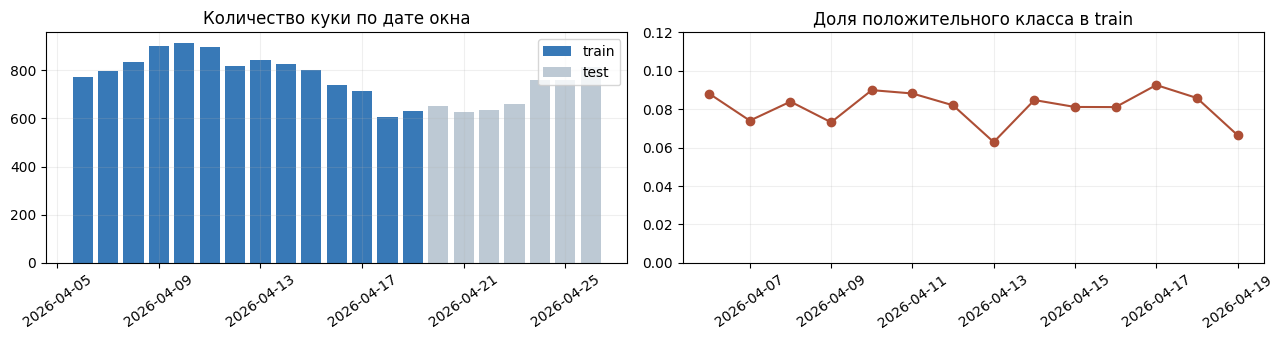

In [3]:
daily_train = train.groupby(train.window_start_ts.dt.date).target.agg(["count", "mean"])
daily_test = test.groupby(test.window_start_ts.dt.date).size()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].bar(pd.to_datetime(daily_train.index), daily_train["count"], label="train", color="#3879b7")
axes[0].bar(pd.to_datetime(daily_test.index), daily_test, label="test", color="#bdc9d4")
axes[0].set_title("Количество куки по дате окна")
axes[0].legend()
axes[1].plot(pd.to_datetime(daily_train.index), daily_train["mean"], marker="o", color="#ad4e35")
axes[1].set_title("Доля положительного класса в train")
axes[1].set_ylim(0, 0.12)
for ax in axes:
    ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
plt.show()

## 2. Подготовка и признаки

Полные дубликаты удаляются **до нормализации строк**: одинаковое время у разных действий само по себе не делает их дубликатами. `web/Web/WEB/desktop` приводятся к `web`, варианты Android и iOS — к своим семействам.

Для интервалов события сортируются по времени внутри куки. Для переходов между действиями, поисковыми страницами и точками курсора исключаются пары, в которых временная отметка неоднозначна. Вторичная сортировка обеспечивает повторяемость, но не считается настоящим порядком действий.

Каждая кука агрегируется независимо. Совместная обработка метаданных train и test здесь экономит повторное чтение файла: межкуковых агрегатов, словарей из тестовой разметки и обучаемых преобразований в `build_features` нет. Словари категорий моделей строятся только при обучении.

In [4]:
features, groups, audit = build_features(events, meta)
display(pd.Series(audit, name="значение").to_frame())
display(pd.DataFrame({
    "группа": list(groups),
    "число признаков": [len(columns) for columns in groups.values()],
}))

# Для аудита оставляем исходные названия событий и исходные строки.
event_windows = events.merge(
    meta[["cookie_id", "window_start_ts", "window_end_ts"]],
    on="cookie_id", validate="many_to_one",
)
inside = (
    event_windows.event_ts.ge(event_windows.window_start_ts)
    & event_windows.event_ts.lt(event_windows.window_end_ts)
)
window_audit = pd.crosstab(event_windows.event_name, inside).rename(
    columns={False: "вне окна", True: "внутри окна, до удаления дублей"}
)
display(window_audit)
(ARTIFACTS / "data_audit.json").write_text(json.dumps(audit, indent=2), encoding="utf-8")
window_audit.to_csv(ARTIFACTS / "events_by_window.csv")
del event_windows

,значение
n_input_events,328905
n_matched_events,328905
n_outside_window,40779
n_duplicate_rows_in_window,4293
n_clean_events,283833
n_cookies_without_events,0


,группа,число признаков
0,baseline_raw,2
1,basic,2
2,metadata,1
3,events,25
4,timing,32
5,rhythm,16
6,diversity,16
7,search,7
8,technical,11
9,pointer,9


col_0,вне окна,"внутри окна, до удаления дублей"
event_name,,
captcha_shown,7928,0
contact_chat_open,577,5548
contact_message_sent,258,2823
contact_phone_show,1028,10288
favorite_add,1753,17296
item_view,12731,108086
login,606,5661
photo_swipe,3433,33084
search_results_view,10604,89798


После фильтрации и удаления дубликатов остаётся **283 833 события**. Исключены **40 779 событий вне окон** и **4 293 повторные строки внутри окон**. У всех 16 000 куки остаются наблюдения.

Особенно показателен `captcha_shown`: все **7 928** таких строк находятся после конца окна. Использование капчи дало бы информацию из будущего. В корректной таблице её счётчик и доля равны нулю. Это проверка данных, а не основание добавлять запрещённый признак.

Пропуски сохраняют смысл. Отсутствие просмотров даёт нулевой счётчик; отсутствие второго события делает интервал неопределённым, поэтому оставляем NaN. Координаты доступны лишь для части событий и платформ: отсутствие координат само по себе не означает бота.

| Группа | Смысл и ограничения |
|---|---|
| `basic`, `events` | Объём активности, состав действий, энтропия типов и отношения контактов/фото к просмотрам. Отношение с нулевым знаменателем остаётся NaN. |
| `timing` | Квантили и разброс интервалов, доли коротких пауз, концентрация по часам и минутам, сессии с разрывом более 30 минут. Часовой пояс исходных времён неизвестен: «ночь» означает 0–5 часов в этих данных. |
| `rhythm` | Ритм внутри сессий, повторяемость интервалов, интервалы отдельно между просмотрами, поиском и листанием фото. Это отделяет типичные действия от длинных перерывов. |
| `diversity`, `search` | Доля уникальных и наиболее частых объектов, энтропия категорий/локаций/запросов, глубина поиска и последовательное листание того же запроса. Тексты запросов и номера объявлений не передаются в модель напрямую. |
| `technical` | Семейства браузера и ОС, признаки HTTP-клиентов/Headless, платформа и их изменения. Версии браузеров и модели телефонов отброшены. Маскировка User-Agent остаётся возможной. |
| `pointer` | Доля наблюдений, повторение точек, разброс координат и расстояния между наблюдаемыми точками. Это не восстановленная траектория мыши; часть величин зависит от размеров экрана. |
| `metadata` | Возраст куки на конец окна. Его полезность проверяется отдельно, поскольку состав новых/старых куки может меняться со временем. |
| `transitions` | Экспериментальная матрица долей переходов между типами событий. В итоговое решение не вошла. |

Реализация находится в `src/features.py`: обычные pandas-агрегации и небольшие функции. Нормированная доля уникальных значений помогает отделить разнообразие от общего количества событий; энтропия дополнительно учитывает неравномерность частот.

### Проверки на маленьком примере

Проверяем границы окна, дубликаты, независимость признаков от порядка строк, будущих событий и target, пустые истории и обработку равных score в метрике. Это свойства расчёта, от которых зависит корректность модели.


In [5]:
check_meta = pd.DataFrame({
    "cookie_id": ["a", "b"],
    "cookie_created_at": pd.to_datetime(["2026-04-01", "2026-04-02"]),
    "window_start_ts": pd.to_datetime(["2026-04-06", "2026-04-06"]),
    "window_end_ts": pd.to_datetime(["2026-04-07", "2026-04-07"]),
})
check_events = pd.DataFrame({
    "cookie_id": ["a"] * 4,
    "event_ts": pd.to_datetime([
        "2026-04-06 00:00:00", "2026-04-06 00:00:05",
        "2026-04-06 00:00:05", "2026-04-06 00:01:00",
    ]),
    "eid": [100, 200, 210, 200],
    "event_name": ["search_results_view", "item_view", "photo_swipe", "item_view"],
    "platform": ["WEB", "web", "desktop", "Web"],
    "user_agent": ["Mozilla/5.0 Chrome/120.0 Safari/537.36"] * 4,
    "item_id": [np.nan, 1, 1, 2],
    "item_category": ["phones"] * 4,
    "item_location": ["moscow"] * 4,
    "seller_type": [None, "private", None, "pro"],
    "search_query": ["phone", None, None, None],
    "search_page": [1.0, np.nan, np.nan, np.nan],
    "pointer_x": [100.0, 200.0, 400.0, 500.0],
    "pointer_y": [100.0, 300.0, 200.0, 500.0],
})


In [6]:
# Начало окна включается, конец — нет. Разные действия в одну секунду сохраняются.
outside = check_events.iloc[:2].copy()
outside["event_ts"] = pd.to_datetime(["2026-04-05 23:59:59", "2026-04-07 00:00:00"])
changed_events = pd.concat([check_events, check_events.iloc[:1], outside], ignore_index=True)
clean_example, raw_example, audit_example = prepare_events(changed_events, check_meta)
assert len(clean_example) == 4
assert len(raw_example) == 5
assert audit_example["n_outside_window"] == 2
assert clean_example.event_ts.min() == check_meta.window_start_ts.iloc[0]
assert clean_example.event_ts.eq("2026-04-06 00:00:05").sum() == 2
print("Границы окна и дубликаты: OK")


Границы окна и дубликаты: OK


In [7]:
check_expected, check_groups, _ = build_features(check_events, check_meta)
check_shuffled, _, _ = build_features(
    check_events.sample(frac=1, random_state=99), check_meta,
)
assert_frame_equal(check_expected, check_shuffled)

future = check_events.copy()
future["event_ts"] += pd.Timedelta(days=1)
future["user_agent"] = "future-information"
unrelated = check_events.copy()
unrelated["cookie_id"] = "not-in-meta"
check_actual, _, _ = build_features(pd.concat([check_events, future, unrelated]), check_meta)
assert_frame_equal(check_expected, check_actual)

check_actual, _, _ = build_features(check_events, check_meta.assign(target=[1, 0]))
assert_frame_equal(check_expected, check_actual)
assert check_actual.loc["b", "n_events"] == 0
assert check_actual.loc["b", "platform_main"] == "unknown"
assert pd.isna(check_actual.loc["b", "gap_mean"])
assert set(check_actual.select_dtypes(exclude="number").columns) == {
    "platform_main", "browser_main", "system_main",
}

check_doubled, _, _ = build_features(pd.concat([check_events, check_events]), check_meta)
clean_columns = check_expected.columns.difference(check_groups["baseline_raw"])
assert_frame_equal(check_expected[clean_columns], check_doubled[clean_columns])

check_single, _, _ = build_features(check_events.iloc[:1], check_meta)
assert check_single.loc["a", "n_events"] == 1
assert pd.isna(check_single.loc["a", "gap_mean"])
check_empty, _, _ = build_features(check_events.iloc[:0], check_meta)
assert list(check_empty.index) == ["a", "b"]
assert check_empty.n_events.eq(0).all()
print("Порядок строк, будущие события, target, дубли и пустые истории: OK")


Порядок строк, будущие события, target, дубли и пустые истории: OK


In [8]:
assert precision_at_recall([1, 0, 1, 1, 1], [5, 4, 3, 2, 1]) == 0.8
assert precision_at_recall([1, 1, 0, 0], [0.5] * 4) == 0.5
print("Официальная метрика: OK")


Официальная метрика: OK


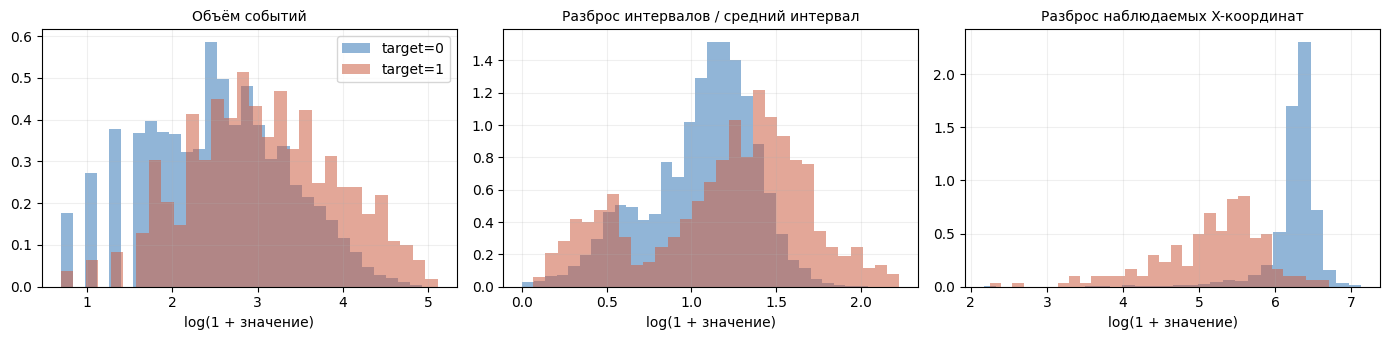

count_captcha_shown                               1
share_captcha_shown                               1
platform_nunique                                  1
pointer_stationary_share                          1
transition_search_results_view__captcha_shown     1
transition_item_view__captcha_shown               1
transition_photo_swipe__captcha_shown             1
transition_seller_page_view__captcha_shown        1
transition_contact_phone_show__captcha_shown      1
transition_contact_chat_open__captcha_shown       1
transition_contact_message_sent__captcha_shown    1
transition_favorite_add__captcha_shown            1
transition_login__captcha_shown                   1
transition_captcha_shown__search_results_view     1
transition_captcha_shown__item_view               1
transition_captcha_shown__photo_swipe             1
transition_captcha_shown__seller_page_view        1
transition_captcha_shown__contact_phone_show      1
transition_captcha_shown__contact_chat_open       1
transition_c

In [9]:
# Описательный анализ использует только период разработки, до отложенных 17–19 апреля.
development_meta = train.loc[train.window_start_ts.lt("2026-04-17")]
eda = features.loc[development_meta.cookie_id].join(development_meta.set_index("cookie_id").target)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, column, title in zip(
    axes,
    ["n_events", "gap_cv", "pointer_x_std"],
    ["Объём событий", "Разброс интервалов / средний интервал", "Разброс наблюдаемых X-координат"],
):
    for label, color in [(0, "#3879b7"), (1, "#cc6044")]:
        values = eda.loc[eda.target.eq(label), column].dropna()
        ax.hist(np.log1p(values), bins=30, density=True, alpha=0.55, label=f"target={label}", color=color)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("log(1 + значение)")
axes[0].legend()
fig.tight_layout()
plt.show()

# Константы остаются в общей схеме, но дерево не может использовать их для разбиения.
display(features.loc[development_meta.cookie_id].nunique().loc[lambda s: s <= 1].rename("уникальных значений"))

## 3. Временная валидация и метрика

Для разработки используются 11–13 апреля (обучение до 11-го) и 14–16 апреля (обучение до 14-го). Отрезок 17–19 апреля оставлен для заключительной оценки выбранного решения; обучение для него заканчивается 16 апреля. Размеры разбиений считаются из данных в следующей ячейке.

Выбираем максимальную точность среди всех порогов, где полнота не ниже 70%. Поэтому нельзя просто считать precision при пороге 0.5 или брать первую точку, достигшую recall 0.7. Равные оценки обрабатываются целиком одной группой. Используется неизменённый официальный `bot_detection_challenge/metric.py`.

Основной критерий выбора — средняя P@R≥0.70 **по отдельным временным отрезкам**. Прогнозы моделей разных фолдов не склеиваются для выбора общего порога. Дополнительно смотрим худший отрезок, Average Precision и ROC-AUC. Здесь AP — `average_precision_score`, а не трапецеидальная площадь под PR-кривой.

Число деревьев фиксируется в конфигурациях; early stopping на проверочном отрезке не используется. Веса классов проверяются экспериментально. Калибровка не требуется для ранжирования; score нельзя автоматически считать откалиброванной вероятностью.


In [10]:
DEV_FOLDS = [
    ("apr11_13", "2026-04-11", "2026-04-14"),
    ("apr14_16", "2026-04-14", "2026-04-17"),
]

fold_rows = []
for fold, start, end in DEV_FOLDS:
    fit = train.window_start_ts.lt(start)
    valid = train.window_start_ts.ge(start) & train.window_start_ts.lt(end)
    assert train.loc[fit, "window_end_ts"].max() <= pd.Timestamp(start)
    fold_rows.append({
        "отрезок": fold, "обучение": int(fit.sum()), "проверка": int(valid.sum()),
        "ботов": int(train.loc[valid, "target"].sum()),
        "P@R70 константы": precision_at_recall(train.loc[valid, "target"], np.zeros(valid.sum())),
    })
display(pd.DataFrame(fold_rows))


,отрезок,обучение,проверка,ботов,P@R70 константы
0,apr11_13,4217,2556,199,0.077856
1,apr14_16,6773,2367,195,0.082383


## 4. Эксперименты: от baseline к итоговой модели

Официальный baseline использует Random Forest, 300 деревьев, `min_samples_leaf=3`, seed 0 и два признака: число событий и число разных объявлений. Для точного сравнения он получает события в окне **до удаления полных дубликатов**, как quickstart. Вариант `clean_rf` проверяет влияние очистки.

Для CatBoost последовательно добавляются состав действий, разнообразие и поиск, затем временные признаки. Полная исходная версия сравнивается с исключением возраста куки, технических признаков и координат. Отдельно проверяется матрица переходов.

Все конфигурации заданы ниже обычными списками словарей. Общие списки групп нужны, чтобы не повторять одни и те же названия в каждом варианте; порядок колонок сохранён.

Функция `run_experiments` повторяет один и тот же цикл для трёх серий: обучение только на прошлом, прогноз на следующих днях и расчёт метрик. Она не подбирает параметры сама. При запуске результаты и прогнозы записываются в `artifacts/experiments/`; никаких готовых журналов для запуска не требуется. Таблицы ниже строятся из результатов этих запусков.


In [11]:
BEHAVIOR_GROUPS = ["basic", "events", "diversity", "search"]
TIMED_GROUPS = BEHAVIOR_GROUPS + ["timing"]
FULL_GROUPS = TIMED_GROUPS + ["metadata", "technical", "pointer"]
NO_AGE_GROUPS = TIMED_GROUPS + ["technical", "pointer"]
RHYTHM_GROUPS = NO_AGE_GROUPS + ["rhythm"]
RHYTHM_AGE_GROUPS = RHYTHM_GROUPS + ["metadata"]

development_configs = [
    {
        "name": "quickstart_rf", "model": "random_forest",
        "groups": ["baseline_raw"],
    },
    {
        "name": "clean_rf", "model": "random_forest",
        "groups": ["basic"],
    },
    {
        "name": "cat_counts", "model": "catboost",
        "groups": ["basic"],
    },
    {
        "name": "cat_behavior", "model": "catboost",
        "groups": BEHAVIOR_GROUPS,
    },
    {
        "name": "cat_behavior_time", "model": "catboost",
        "groups": TIMED_GROUPS,
    },
    {
        "name": "cat_full", "model": "catboost",
        "groups": FULL_GROUPS,
    },
    {
        "name": "cat_no_technical", "model": "catboost",
        "groups": ["basic", "events", "diversity", "search", "timing", "metadata", "pointer"],
    },
    {
        "name": "cat_no_metadata", "model": "catboost",
        "groups": NO_AGE_GROUPS,
    },
    {
        "name": "cat_no_pointer", "model": "catboost",
        "groups": ["basic", "events", "diversity", "search", "timing", "metadata", "technical"],
    },
    {
        "name": "cat_transitions", "model": "catboost",
        "groups": ["basic", "events", "diversity", "search", "timing", "metadata", "technical", "pointer", "transitions"],
    },
]

refinement_configs = [
    {
        "name": "cat_onehot", "model": "catboost",
        "groups": NO_AGE_GROUPS,
        "params": {"one_hot_max_size": 16},
    },
    {
        "name": "cat_rhythm", "model": "catboost",
        "groups": RHYTHM_GROUPS,
        "params": {"one_hot_max_size": 16},
    },
    {
        "name": "cat_rhythm_age", "model": "catboost",
        "groups": RHYTHM_AGE_GROUPS,
        "params": {"one_hot_max_size": 16},
    },
    {
        "name": "cat_rhythm_d4", "model": "catboost",
        "groups": RHYTHM_GROUPS,
        "params": {"one_hot_max_size": 16, "depth": 4, "iterations": 1000, "l2_leaf_reg": 8},
    },
    {
        "name": "cat_rhythm_d6", "model": "catboost",
        "groups": RHYTHM_GROUPS,
        "params": {"one_hot_max_size": 16, "depth": 6, "iterations": 1000, "learning_rate": 0.035, "l2_leaf_reg": 8},
    },
    {
        "name": "cat_rhythm_long", "model": "catboost",
        "groups": RHYTHM_GROUPS,
        "params": {"one_hot_max_size": 16, "iterations": 1500, "learning_rate": 0.03, "l2_leaf_reg": 8},
    },
    {
        "name": "cat_rhythm_weighted", "model": "catboost",
        "groups": RHYTHM_GROUPS,
        "params": {"one_hot_max_size": 16, "class_weights": [1, 3]},
    },
    {
        "name": "cat_rhythm_no_captcha", "model": "catboost",
        "groups": RHYTHM_GROUPS,
        "params": {"one_hot_max_size": 16},
        "exclude_columns": ["count_captcha_shown", "share_captcha_shown"],
    },
    {
        "name": "cat_rhythm_transitions", "model": "catboost",
        "groups": ["basic", "events", "diversity", "search", "timing", "technical", "pointer", "rhythm", "transitions"],
        "params": {"one_hot_max_size": 16},
    },
]

robustness_configs = [
    {
        "name": "cat_onehot_age", "model": "catboost",
        "groups": ["basic", "events", "diversity", "search", "timing", "technical", "pointer", "metadata"],
        "params": {"one_hot_max_size": 16},
    },
    {
        "name": "cat_rhythm_age_d4", "model": "catboost",
        "groups": RHYTHM_AGE_GROUPS,
        "params": {"one_hot_max_size": 16, "depth": 4, "iterations": 1000, "l2_leaf_reg": 8},
    },
    {
        "name": "cat_rhythm_age_d6", "model": "catboost",
        "groups": RHYTHM_AGE_GROUPS,
        "params": {"one_hot_max_size": 16, "depth": 6, "iterations": 1000, "learning_rate": 0.035, "l2_leaf_reg": 8},
    },
    {
        "name": "cat_rhythm_age_weighted", "model": "catboost",
        "groups": RHYTHM_AGE_GROUPS,
        "params": {"one_hot_max_size": 16, "class_weights": [1, 3]},
    },
    {
        "name": "cat_rhythm_age_seed17", "model": "catboost",
        "groups": RHYTHM_AGE_GROUPS,
        "params": {"one_hot_max_size": 16, "random_seed": 17},
    },
    {
        "name": "cat_rhythm_age_seed2026", "model": "catboost",
        "groups": RHYTHM_AGE_GROUPS,
        "params": {"one_hot_max_size": 16, "random_seed": 2026},
    },
    {
        "name": "hgb_rhythm_age", "model": "hist_gradient_boosting",
        "groups": RHYTHM_AGE_GROUPS,
    },
    {
        "name": "hgb_rhythm_noage", "model": "hist_gradient_boosting",
        "groups": RHYTHM_GROUPS,
    },
]

all_configs = development_configs + refinement_configs + robustness_configs


In [12]:
def run_experiments(train, features, groups, configs, folds=DEV_FOLDS, output_dir="artifacts/experiments/development"):
    """Фиксированное число деревьев: validation не участвует даже в early stopping."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    results, predictions = [], []
    X = features.loc[train.cookie_id]
    y = train.target.to_numpy()
    dates = train.window_start_ts
    for config in configs:
        columns = feature_columns(config, groups)
        for fold, start, end in folds:
            is_fit = dates.lt(start).to_numpy()
            is_valid = (dates.ge(start) & dates.lt(end)).to_numpy()
            started = perf_counter()
            fitted = fit_configuration(config, X.loc[is_fit], y[is_fit], groups)
            score = predict_configuration(fitted, X.loc[is_valid])
            result = {
                "experiment": config["name"], "fold": fold,
                "n_train": int(is_fit.sum()), "n_valid": int(is_valid.sum()),
                "n_positive": int(y[is_valid].sum()), "n_features": len(columns),
                **evaluate(y[is_valid], score),
                "elapsed_seconds": round(perf_counter() - started, 3),
            }
            results.append(result)
            predictions.append(pd.DataFrame({
                "cookie_id": train.loc[is_valid, "cookie_id"].to_numpy(),
                "target": y[is_valid], "score": score,
                "experiment": config["name"], "fold": fold,
            }))
            print(config["name"], fold, f"P@R70={result['precision_at_recall70']:.4f}", flush=True)
    results = pd.DataFrame(results)
    predictions = pd.concat(predictions, ignore_index=True)
    results.to_csv(output_dir / "results.csv", index=False)
    predictions.to_csv(output_dir / "predictions.csv", index=False)
    manifest = {
        "configs": configs, "folds": folds, "catboost_defaults": CAT_DEFAULTS,
        "model_parameters": {config["name"]: make_model(config).get_params() for config in configs},
        "feature_columns": {config["name"]: feature_columns(config, groups) for config in configs},
    }
    (output_dir / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
    return results, predictions


def compare_experiments(results):
    summary = results.groupby("experiment").agg(
        precision_mean=("precision_at_recall70", "mean"),
        precision_min=("precision_at_recall70", "min"),
        ap_mean=("average_precision", "mean"),
        n_features=("n_features", "first"),
    )
    return summary.sort_values(["precision_mean", "precision_min"], ascending=False)


In [13]:
development_results, development_predictions = run_experiments(
    train, features, groups, development_configs,
    output_dir=ARTIFACTS / "experiments/development",
)
display(compare_experiments(development_results).round(4))


quickstart_rf apr11_13 P@R70=0.0931


quickstart_rf apr14_16 P@R70=0.1047


clean_rf apr11_13 P@R70=0.0932


clean_rf apr14_16 P@R70=0.0996


cat_counts apr11_13 P@R70=0.0957


cat_counts apr14_16 P@R70=0.1262


... (11 outputs left out)

cat_no_pointer apr14_16 P@R70=0.5310


cat_transitions apr11_13 P@R70=0.6812


cat_transitions apr14_16 P@R70=0.6954


,precision_mean,precision_min,ap_mean,n_features
experiment,,,,
cat_no_metadata,0.7175,0.6931,0.7674,102
cat_no_technical,0.6933,0.6380,0.7628,92
cat_transitions,0.6883,0.6812,0.7576,203
cat_full,0.6834,0.6481,0.7694,103
cat_behavior_time,0.5505,0.5490,0.7052,82
cat_no_pointer,0.5210,0.5109,0.7070,94
cat_behavior,0.3051,0.2591,0.5748,50
cat_counts,0.1109,0.0957,0.2439,2
quickstart_rf,0.0989,0.0931,0.2360,2


Количество событий само по себе даёт слабое качество: P@R70 около 0.10. Добавление поведения поднимает результат до 0.26–0.35, времени — примерно до 0.55 на обоих отрезках.

В исходном полном варианте (`cat_full`) результаты 0.6481/0.7188. Без признаков курсора они падают до 0.5109/0.5310, а удаление возраста куки улучшает оба отрезка до 0.6931/0.7419. Матрица переходов не даёт устойчивого выигрыша. Это выводы именно об этих конфигурациях, а не универсальная оценка полезности каждого признака.

In [14]:
refinement_results, refinement_predictions = run_experiments(
    train, features, groups, refinement_configs,
    output_dir=ARTIFACTS / "experiments/refinement",
)
display(compare_experiments(refinement_results).round(4))


cat_onehot apr11_13 P@R70=0.6897


cat_onehot apr14_16 P@R70=0.7249


cat_rhythm apr11_13 P@R70=0.6931


cat_rhythm apr14_16 P@R70=0.7326


cat_rhythm_age apr11_13 P@R70=0.7421


cat_rhythm_age apr14_16 P@R70=0.7541


... (9 outputs left out)

cat_rhythm_no_captcha apr14_16 P@R70=0.7326


cat_rhythm_transitions apr11_13 P@R70=0.6796


cat_rhythm_transitions apr14_16 P@R70=0.7405


,precision_mean,precision_min,ap_mean,n_features
experiment,,,,
cat_rhythm_age,0.7481,0.7421,0.7722,119
cat_rhythm_d6,0.7372,0.7216,0.7761,118
cat_rhythm_weighted,0.7329,0.7292,0.7768,118
cat_rhythm_long,0.7249,0.7157,0.7738,118
cat_rhythm_d4,0.7161,0.7035,0.7726,118
cat_rhythm,0.7128,0.6931,0.7731,118
cat_rhythm_no_captcha,0.7128,0.6931,0.7731,116
cat_rhythm_transitions,0.7101,0.6796,0.7610,218
cat_onehot,0.7073,0.6897,0.7651,102


Во второй серии проверяются one-hot для небольших категориальных словарей, отдельный ритм внутри сессий и типов событий, глубина деревьев, число итераций, регуляризация и веса классов.

Интересный результат: после добавления `rhythm` и перехода к one-hot возраст куки становится полезен: `cat_rhythm_age` получает 0.7421/0.7541 против 0.6931/0.7326 без возраста. Вывод первой серии об удалении возраста нельзя переносить на другую модель без проверки.

Удаление явных признаков капчи ничего не изменило: после правильной фильтрации они константны. Больше деревьев, веса классов и матрица переходов не улучшили оба отрезка относительно лидера этой серии.

In [15]:
robustness_results, robustness_predictions = run_experiments(
    train, features, groups, robustness_configs,
    output_dir=ARTIFACTS / "experiments/robustness",
)
display(compare_experiments(robustness_results).round(4))


cat_onehot_age apr11_13 P@R70=0.6931


cat_onehot_age apr14_16 P@R70=0.7173


cat_rhythm_age_d4 apr11_13 P@R70=0.7216


cat_rhythm_age_d4 apr14_16 P@R70=0.7446


cat_rhythm_age_d6 apr11_13 P@R70=0.7487


cat_rhythm_age_d6 apr14_16 P@R70=0.7366


... (7 outputs left out)

hgb_rhythm_age apr14_16 P@R70=0.7405


hgb_rhythm_noage apr11_13 P@R70=0.7330


hgb_rhythm_noage apr14_16 P@R70=0.6782


,precision_mean,precision_min,ap_mean,n_features
experiment,,,,
cat_rhythm_age_seed17,0.7654,0.7568,0.7773,119
hgb_rhythm_age,0.7446,0.7405,0.7665,119
cat_rhythm_age_d6,0.7426,0.7366,0.7758,119
cat_rhythm_age_weighted,0.7376,0.7306,0.7777,119
cat_rhythm_age_seed2026,0.7340,0.7113,0.7685,119
cat_rhythm_age_d4,0.7331,0.7216,0.7684,119
hgb_rhythm_noage,0.7056,0.6782,0.7661,118
cat_onehot_age,0.7052,0.6931,0.7650,103


В третьей серии уточняются глубина и веса для набора с возрастом; повторяются seed 17 и 2026 при исходном seed 42. Также проверяется HistGradientBoosting из scikit-learn. Его one-hot-преобразование обучается только на тренировочной части, а неизвестные категории при прогнозе игнорируются.

Seed влияет на результат: средние значения одинаковой конфигурации составляют примерно 0.7481, 0.7654 и 0.7340. Выбор seed — тоже подбор гиперпараметра; эти прогоны нельзя выдавать за три независимых теста. Небольшое превосходство лидера на двух отрезках ещё не доказывает статистическое преимущество.

In [16]:
def evaluate_ensembles(predictions, specs, configs, groups, output_dir="artifacts/experiments/ensembles"):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    by_name = {config["name"]: config for config in configs}
    wide = predictions.pivot(index=["fold", "cookie_id", "target"], columns="experiment", values="score")
    results, ensemble_predictions, comparisons, resolved = [], [], [], []
    for spec in specs:
        config = {"name": spec["name"], "members": [by_name[name] for name in spec["members"]]}
        resolved.append(config)
        if wide[spec["members"]].isna().any().any():
            raise ValueError("Не для всех куки есть прогнозы участников ансамбля")
        mean_score = wide[spec["members"]].mean(axis=1)
        frame = mean_score.rename("score").reset_index()
        frame["experiment"] = spec["name"]
        ensemble_predictions.append(frame)
        for fold, subset in frame.groupby("fold"):
            y, score = subset.target.to_numpy(), subset.score.to_numpy()
            results.append({
                "experiment": spec["name"], "fold": fold, "n_valid": len(y),
                "n_positive": int(y.sum()), "n_features": len(feature_columns(config, groups)),
                **evaluate(y, score),
            })
            reference = wide.loc[fold, "cat_rhythm_age"].to_numpy()
            comparisons.append({
                "experiment": spec["name"], "fold": fold,
                "reference": "cat_rhythm_age", **paired_bootstrap(y, reference, score),
            })
    results = pd.DataFrame(results)
    combined = pd.concat(ensemble_predictions, ignore_index=True)
    results.to_csv(output_dir / "results.csv", index=False)
    combined.to_csv(output_dir / "predictions.csv", index=False)
    paired_results = pd.DataFrame(comparisons)
    paired_results.to_csv(output_dir / "paired_bootstrap.csv", index=False)
    (output_dir / "configs.json").write_text(json.dumps(resolved, ensure_ascii=False, indent=2), encoding="utf-8")
    return results, combined, paired_results


In [17]:
all_results = pd.concat(
    [development_results, refinement_results, robustness_results], ignore_index=True,
)
all_predictions = pd.concat(
    [development_predictions, refinement_predictions, robustness_predictions], ignore_index=True,
)
ensemble_specs = [
    {"name": "cat_seed_mean", "members": ["cat_rhythm_age", "cat_rhythm_age_seed17", "cat_rhythm_age_seed2026"]},
    {"name": "cat_depth_mean", "members": ["cat_rhythm_age", "cat_rhythm_age_d6"]},
    {"name": "cat_seed_depth_mean", "members": ["cat_rhythm_age", "cat_rhythm_age_seed17", "cat_rhythm_age_seed2026", "cat_rhythm_age_d6"]},
    {"name": "cat_hgb_mean", "members": ["cat_rhythm_age", "cat_rhythm_age_seed17", "cat_rhythm_age_seed2026", "hgb_rhythm_age"]},
]
ensemble_results, ensemble_predictions, paired_results = evaluate_ensembles(
    all_predictions, ensemble_specs, all_configs, groups,
    output_dir=ARTIFACTS / "experiments/ensembles",
)
display(compare_experiments(ensemble_results).round(4))
display(paired_results.round(4))


,precision_mean,precision_min,ap_mean,n_features
experiment,,,,
cat_depth_mean,0.7637,0.7582,0.7761,119
cat_seed_depth_mean,0.7631,0.7609,0.7776,119
cat_hgb_mean,0.7590,0.7446,0.7809,119
cat_seed_mean,0.7589,0.7486,0.7761,119


,experiment,fold,reference,difference,lower,upper
0,cat_seed_mean,apr11_13,cat_rhythm_age,0.0271,-0.0540,0.0799
1,cat_seed_mean,apr14_16,cat_rhythm_age,-0.0055,-0.0462,0.0642
2,cat_depth_mean,apr11_13,cat_rhythm_age,0.0271,-0.0620,0.0756
3,cat_depth_mean,apr14_16,cat_rhythm_age,0.0041,-0.0333,0.0525
4,cat_seed_depth_mean,apr11_13,cat_rhythm_age,0.0188,-0.0540,0.0893
5,cat_seed_depth_mean,apr14_16,cat_rhythm_age,0.0113,-0.0462,0.0684
6,cat_hgb_mean,apr11_13,cat_rhythm_age,0.0314,-0.0598,0.1240
7,cat_hgb_mean,apr14_16,cat_rhythm_age,-0.0095,-0.0485,0.0878


Для ансамблей усредняются обычные оценки с равными весами: разные seed, разные глубины и CatBoost с HistGradientBoosting. Весов, подобранных по скрытому тесту, нет.

Парный bootstrap пересэмплирует одни и те же куки для одиночной модели и ансамбля. В таблице сравнение ведётся с `cat_rhythm_age`, seed 42. Интервалы разницы пересекают ноль; это не подтверждает уверенного преимущества ансамблей. Лучший ансамбль по среднему (0.7637) также не превосходит лучшую одиночную конфигурацию (0.7654). Поэтому дополнительное обучение нескольких моделей не включено в итоговый pipeline.

,precision_mean,precision_min,ap_mean,n_features,apr11_13,apr14_16
experiment,,,,,,
cat_rhythm_age_seed17,0.7654,0.7568,0.7773,119,0.7568,0.7740
cat_depth_mean,0.7637,0.7582,0.7761,119,0.7692,0.7582
cat_seed_depth_mean,0.7631,0.7609,0.7776,119,0.7609,0.7654
cat_hgb_mean,0.7590,0.7446,0.7809,119,0.7735,0.7446
cat_seed_mean,0.7589,0.7486,0.7761,119,0.7692,0.7486
cat_rhythm_age,0.7481,0.7421,0.7722,119,0.7421,0.7541
hgb_rhythm_age,0.7446,0.7405,0.7665,119,0.7487,0.7405
cat_rhythm_age_d6,0.7426,0.7366,0.7758,119,0.7487,0.7366
cat_rhythm_age_weighted,0.7376,0.7306,0.7777,119,0.7306,0.7446


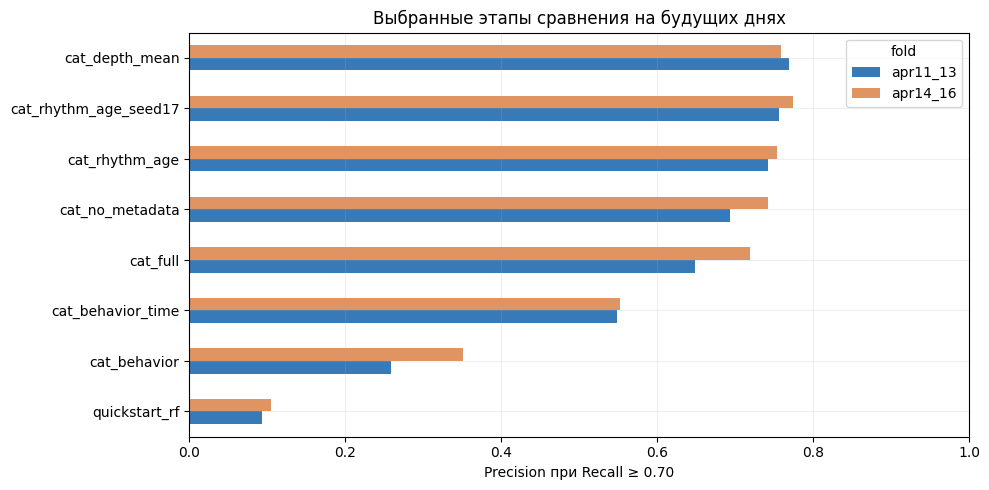

In [18]:
combined_results = pd.concat([all_results, ensemble_results], ignore_index=True)
fold_scores = combined_results.pivot(
    index="experiment", columns="fold", values="precision_at_recall70",
)
comparison = compare_experiments(combined_results).join(fold_scores)
display(comparison.round(4))
comparison.to_csv(ARTIFACTS / "experiment_summary.csv")

shown = [
    "quickstart_rf", "cat_behavior", "cat_behavior_time", "cat_full",
    "cat_no_metadata", "cat_rhythm_age", "cat_rhythm_age_seed17", "cat_depth_mean",
]
plot_table = pd.concat([all_results, ensemble_results]).pivot(
    index="experiment", columns="fold", values="precision_at_recall70",
).loc[shown]
ax = plot_table.plot.barh(figsize=(10, 5), color=["#3879b7", "#df9462"])
ax.set_xlim(0, 1)
ax.set_xlabel("Precision при Recall ≥ 0.70")
ax.set_ylabel("")
ax.set_title("Выбранные этапы сравнения на будущих днях")
plt.tight_layout()
plt.show()


## 5. Зафиксированное решение

Выбрана одна модель `cat_rhythm_age_seed17`: **700 деревьев глубины 5**, learning rate 0.05, L2-регуляризация 5, seed 17, `one_hot_max_size=16`, CPU. Входная таблица содержит **119 признаков**, включая три категориальных семейства; константы дерево не использует.

Результаты разработки: **0.7568** на 11–13 апреля и **0.7740** на 14–16 апреля. Более глубокая модель улучшает один отрезок и ухудшает другой; ансамбль не выигрывает у выбранной одиночной модели по среднему.

Конфигурация явно задана в следующей ячейке. Она была зафиксирована до открытия 17–19 апреля и не выбирается заново по заключительной проверке. Поиск по 31 варианту делает оценки разработки оптимистичными — именно поэтому нужен отдельный последний отрезок.


In [19]:
selected = {
    "name": "cat_rhythm_age_seed17",
    "model": "catboost",
    "groups": ["basic", "events", "diversity", "search", "timing", "technical", "pointer", "rhythm", "metadata"],
    "params": {"iterations": 700, "depth": 5, "learning_rate": 0.05, "l2_leaf_reg": 5, "random_seed": 17, "one_hot_max_size": 16, "loss_function": "Logloss", "thread_count": 6, "task_type": "CPU", "verbose": False, "allow_writing_files": False},
}
selected_columns = feature_columns(selected, groups)
print("Выбранная конфигурация:", selected["name"])
print("Признаков:", len(selected_columns))
display(pd.Series(selected["params"], name="значение").to_frame())

feature_catalog = pd.DataFrame([
    {"group": group, "feature": column, "selected": column in selected_columns}
    for group, columns in groups.items() for column in columns
])
feature_catalog.to_csv(ARTIFACTS / "feature_catalog.csv", index=False)


Выбранная конфигурация: cat_rhythm_age_seed17
Признаков: 119


,значение
iterations,700
depth,5
learning_rate,0.05
l2_leaf_reg,5
random_seed,17
one_hot_max_size,16
loss_function,Logloss
thread_count,6
task_type,CPU
verbose,False


## 6. Последняя проверка: 17–19 апреля

Здесь модель обучается на 6–16 апреля. После этой проверки признаки, seed и настройки не меняются. При повторном выполнении ноутбука заново вычисляется тот же эксперимент; он не превращается в новую возможность подбора.

Порог из этой выборки нужен только для воспроизведения официальной метрики и описания ошибок. Он не передаётся на Stepik и не объявляется готовым порогом для эксплуатации.

In [20]:
is_fit = train.window_start_ts.lt("2026-04-17").to_numpy()
is_valid = train.window_start_ts.ge("2026-04-17").to_numpy()
assert train.loc[is_fit, "window_end_ts"].max() <= pd.Timestamp("2026-04-17")
X_train = features.loc[train.cookie_id]
y_train = train.target.to_numpy()

baseline = {"name": "quickstart_rf", "model": "random_forest", "groups": ["baseline_raw"]}
holdout_rows, holdout_frames, holdout_models = [], [], {}
for config in [baseline, selected]:
    fit_started = perf_counter()
    fitted = fit_configuration(config, X_train.loc[is_fit], y_train[is_fit], groups)
    score = predict_configuration(fitted, X_train.loc[is_valid])
    holdout_rows.append({
        "experiment": config["name"], "fold": "apr17_19",
        "n_train": int(is_fit.sum()), "n_valid": int(is_valid.sum()),
        "n_positive": int(y_train[is_valid].sum()),
        "n_features": len(feature_columns(config, groups)),
        **evaluate(y_train[is_valid], score),
        "elapsed_seconds": round(perf_counter() - fit_started, 3),
    })
    holdout_frames.append(pd.DataFrame({
        "cookie_id": train.loc[is_valid, "cookie_id"].to_numpy(),
        "target": y_train[is_valid], "score": score, "experiment": config["name"],
    }))
    holdout_models[config["name"]] = fitted

holdout_results = pd.DataFrame(holdout_rows)
holdout_predictions = pd.concat(holdout_frames, ignore_index=True)
holdout_results.to_csv(ARTIFACTS / "holdout_results.csv", index=False)
holdout_predictions.to_csv(ARTIFACTS / "holdout_predictions.csv", index=False)

final_validation = holdout_predictions.loc[
    holdout_predictions.experiment.eq(selected["name"])
].copy()
point = best_operating_point(final_validation.target, final_validation.score)
holdout_diagnostics = {
    "operating_point": point,
    "bootstrap95": bootstrap_precision(final_validation.target, final_validation.score),
}
(ARTIFACTS / "holdout_diagnostics.json").write_text(
    json.dumps(holdout_diagnostics, indent=2), encoding="utf-8",
)

segment_predictions = final_validation.merge(
    train[["cookie_id", "window_start_ts"]], on="cookie_id", validate="one_to_one",
).merge(features[["platform_main"]], on="cookie_id", validate="one_to_one")
segment_predictions["day"] = segment_predictions.window_start_ts.dt.date.astype(str)
by_platform = segment_report(segment_predictions, "platform_main", point["threshold"])
by_day = segment_report(segment_predictions, "day", point["threshold"])
by_platform.to_csv(ARTIFACTS / "holdout_by_platform_main.csv", index=False)
by_day.to_csv(ARTIFACTS / "holdout_by_day.csv", index=False)

display(holdout_results.round(4))
display(pd.Series(point, name="значение").to_frame())
print("Bootstrap 95%:", holdout_diagnostics["bootstrap95"])


,experiment,fold,n_train,n_valid,n_positive,n_features,precision_at_recall70,average_precision,roc_auc,recall_at_fpr01,elapsed_seconds
0,quickstart_rf,apr17_19,9140,1951,160,2,0.1025,0.1746,0.6074,0.0750,0.493
1,cat_rhythm_age_seed17,apr17_19,9140,1951,160,119,0.7308,0.7918,0.9366,0.6062,4.951


,значение
threshold,0.246162
precision,0.730769
recall,0.712500
tp,114.000000
fp,42.000000
fn,46.000000
tn,1749.000000


Bootstrap 95%: {'lower': 0.6384115744870651, 'upper': 0.8788181818181818, 'repetitions': 1000}


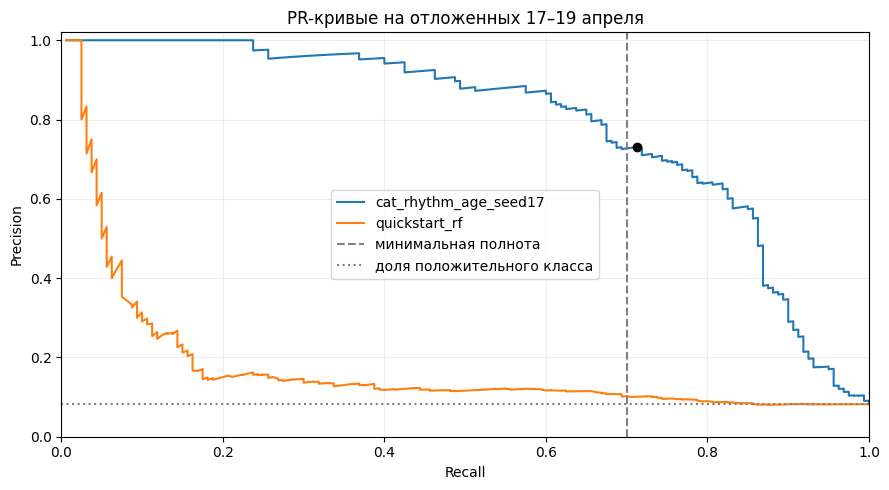

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))
for name, subset in holdout_predictions.groupby("experiment"):
    precision, recall = pr_curve(subset.target, subset.score)
    ax.plot(recall, precision, label=name)
ax.axvline(0.7, color="gray", linestyle="--", label="минимальная полнота")
ax.axhline(final_validation.target.mean(), color="gray", linestyle=":", label="доля положительного класса")
point = holdout_diagnostics["operating_point"]
ax.scatter([point["recall"]], [point["precision"]], color="black", zorder=5)
ax.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02))
ax.set_title("PR-кривые на отложенных 17–19 апреля")
ax.legend()
plt.tight_layout()
plt.show()


На последнем отрезке получено **P@R≥0.70 = 0.7308**, **AP = 0.7918**, **ROC-AUC = 0.9366**. У baseline P@R70 = 0.1025.

В лучшей допустимой точке модель отмечает 156 куки: **114 положительных и 42 отрицательных**, recall = **0.7125**. Пропущено 46 положительных примеров. Это показывает, почему даже высокий ROC-AUC не означает почти безошибочное обнаружение при нужной полноте.

Bootstrap по кукам даёт примерно **[0.638; 0.879]** для P@R70. Интервал широкий: положительных примеров только 160, метрика максимизируется по порогам. Пересэмплирование отражает лишь неопределённость на данном отрезке, предполагает независимость куки и не учитывает новый вид ботов или сдвиг следующей недели.

In [22]:
# Проверяем перенос порога: выбираем его на 14–16 апреля, не на последнем отрезке.
previous = all_predictions.loc[
    all_predictions.experiment.eq(selected["name"]) & all_predictions.fold.eq("apr14_16")
]
previous_threshold = best_operating_point(previous.target, previous.score)["threshold"]
final_validation = holdout_predictions.loc[holdout_predictions.experiment.eq(selected["name"])]
flagged = final_validation.score.ge(previous_threshold)
tp = int((flagged & final_validation.target.eq(1)).sum())
fp = int((flagged & final_validation.target.eq(0)).sum())
threshold_transfer = {
    "threshold_from_apr14_16": previous_threshold,
    "precision_on_apr17_19": tp / flagged.sum(),
    "recall_on_apr17_19": tp / final_validation.target.sum(),
    "tp": tp, "fp": fp,
}
display(pd.Series(threshold_transfer, name="значение").to_frame())
(ARTIFACTS / "threshold_transfer.json").write_text(
    json.dumps(threshold_transfer, indent=2), encoding="utf-8",
)

,значение
threshold_from_apr14_16,0.200449
precision_on_apr17_19,0.713415
recall_on_apr17_19,0.731250
tp,117.000000
fp,47.000000


156

При переносе порога 0.20045 с предыдущего отрезка на последний получаем precision **0.7134**, recall **0.73125**. Это более близкая к эксплуатации проверка фиксированного порога. Для задания всё равно отправляется непрерывный score: система сама перебирает пороги.

В таблицах ниже `precision_at_recall70` пересчитывается внутри каждого сегмента, а колонки `*_fixed_threshold` используют единый порог 0.24616 из общей заключительной проверки. Это разные вопросы: качество ранжирования внутри сегмента и распределение ошибок при одном общем решении.

In [23]:
display(by_platform.round(4))
display(by_day.round(4))


,segment,n,positives,tp_fixed_threshold,fp_fixed_threshold,recall_fixed_threshold,precision_fixed_threshold,precision_at_recall70,average_precision,roc_auc,recall_at_fpr01
0,android,800,54,32,17,0.5926,0.6531,0.6230,0.6962,0.9035,0.5185
1,ios,107,4,2,2,0.5000,0.5000,0.1667,0.4264,0.7184,0.2500
2,web,1044,102,80,23,0.7843,0.7767,0.8571,0.8537,0.9591,0.6765


,segment,n,positives,tp_fixed_threshold,fp_fixed_threshold,recall_fixed_threshold,precision_fixed_threshold,precision_at_recall70,average_precision,roc_auc,recall_at_fpr01
0,2026-04-17,713,66,47,9,0.7121,0.8393,0.8393,0.8175,0.9170,0.6515
1,2026-04-18,606,52,36,15,0.6923,0.7059,0.7115,0.7600,0.9326,0.5385
2,2026-04-19,632,42,31,18,0.7381,0.6327,0.7895,0.8122,0.9743,0.5952


На web P@R70 = 0.8571, на Android — 0.6230. Общий порог находит около 78% положительных web-примеров и 59% Android-примеров. Значит, общая полнота ≥70% не гарантирует такую же полноту на каждой платформе.

Для iOS есть всего **четыре** положительных примера. Оценка P@R70 = 0.1667 слишком нестабильна для уверенного вывода. Отдельные платформенные модели или пороги здесь не подбирались: эта проверка выполняется после фиксации решения.

## 7. Что использует модель и где ошибается

Важность по перестановкам измеряет падение официальной метрики при перемешивании группы признаков на отложенной выборке. Колонки одной группы переставляются вместе, чтобы не разрушать их внутренние связи.

Это диагностическая проверка уже выбранной модели. Она не измеряет причинный эффект и может занижать важность взаимозаменяемых групп. По этой таблице после открытия последнего отрезка признаки не удаляются.

,group,mean_drop,std_drop,repetitions
3,timing,0.2383,0.0301,10
8,pointer,0.2314,0.0511,10
5,diversity,0.2210,0.0343,10
2,events,0.0572,0.0196,10
4,rhythm,0.0521,0.0368,10
7,technical,0.0140,0.0143,10
6,search,0.0139,0.0202,10
1,metadata,0.0047,0.0115,10
0,basic,-0.0256,0.0191,10


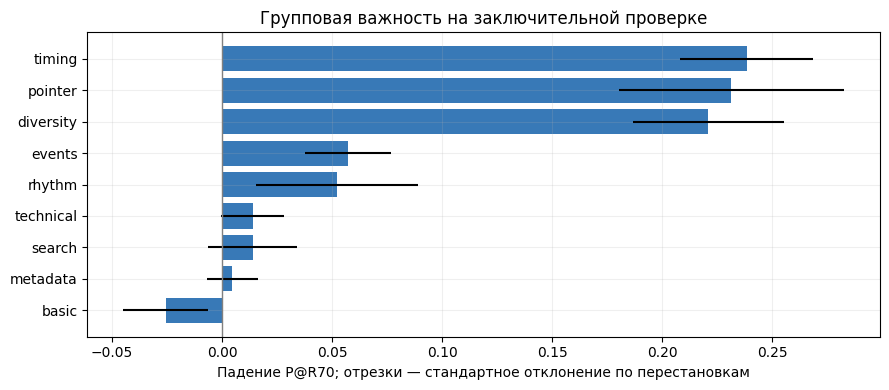

,0
pointer_x_std,8.608502
item_id_unique_share,5.448379
gap_le_60_share,3.399057
within_session_gap_mean,3.287727
item_category_entropy,2.867780
item_category_unique,2.814600
search_page_mean,2.576826
gap_q75,2.565217
pointer_distance_mean,2.529841
within_session_gap_cv,2.262138


In [24]:
is_holdout = train.window_start_ts.ge("2026-04-17")
holdout_X = features.loc[train.loc[is_holdout, "cookie_id"]]
holdout_y = train.loc[is_holdout, "target"].to_numpy()
importance = group_permutation_importance(
    holdout_models[selected["name"]], holdout_X, holdout_y, groups, repetitions=10,
)
importance.to_csv(ARTIFACTS / "group_importance.csv", index=False)
display(importance.round(4))

plot_importance = importance.sort_values("mean_drop")
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(plot_importance["group"], plot_importance.mean_drop, xerr=plot_importance.std_drop, color="#3879b7")
ax.axvline(0, color="gray", linewidth=1)
ax.set_xlabel("Падение P@R70; отрезки — стандартное отклонение по перестановкам")
ax.set_title("Групповая важность на заключительной проверке")
plt.tight_layout()
plt.show()

model, model_columns = holdout_models[selected["name"]][0]
individual_importance = pd.Series(model.feature_importances_, index=model_columns).sort_values(ascending=False)
individual_importance.rename("catboost_importance").to_csv(ARTIFACTS / "feature_importance.csv")
display(individual_importance.head(15).to_frame())

In [25]:
error_columns = [
    "platform_main", "browser_main", "n_events", "cookie_age_days",
    "gap_median", "within_session_gap_cv", "item_id_unique_share",
    "pointer_share", "pointer_x_std",
]
errors = final_validation.set_index("cookie_id").join(features[error_columns])
errors["predicted_bot"] = errors.score.ge(point["threshold"])
false_positives = errors.loc[errors.target.eq(0) & errors.predicted_bot].sort_values("score", ascending=False)
false_negatives = errors.loc[errors.target.eq(1) & ~errors.predicted_bot].sort_values("score")
false_positives.to_csv(ARTIFACTS / "false_positives.csv")
false_negatives.to_csv(ARTIFACTS / "false_negatives.csv")

print("Отрицательные примеры с самыми высокими оценками:")
display(false_positives.head(6))
print("Положительные примеры с самыми низкими оценками:")
display(false_negatives.head(6))

Отрицательные примеры с самыми высокими оценками:


,target,score,experiment,platform_main,browser_main,n_events,cookie_age_days,gap_median,within_session_gap_cv,item_id_unique_share,pointer_share,pointer_x_std,predicted_bot
cookie_id,,,,,,,,,,,,,
ck_92819ececca6e11b,0,0.954744,cat_rhythm_age_seed17,web,chrome,17.0,88.959618,18.0,0.683820,1.000000,1.000000,82.024969,True
ck_e9ed95edb6b7bbf0,0,0.950943,cat_rhythm_age_seed17,web,yandex,19.0,1.426956,16.0,0.420999,0.933333,0.000000,NaN,True
ck_287187374bd47bfc,0,0.859948,cat_rhythm_age_seed17,android,chrome,18.0,1.230810,15.0,0.403949,0.818182,0.000000,NaN,True
ck_2bb512b98c5c8599,0,0.833257,cat_rhythm_age_seed17,web,yandex,24.0,3.437998,17.0,0.737985,0.857143,0.958333,181.140807,True
ck_4a68a718ff52606b,0,0.812260,cat_rhythm_age_seed17,web,firefox,41.0,48.344803,25.5,3.810237,0.620690,0.951220,83.083596,True
ck_1f9b1983e657d463,0,0.798064,cat_rhythm_age_seed17,web,firefox,22.0,1.271713,18.0,0.573098,0.666667,0.000000,NaN,True


Положительные примеры с самыми низкими оценками:


,target,score,experiment,platform_main,browser_main,n_events,cookie_age_days,gap_median,within_session_gap_cv,item_id_unique_share,pointer_share,pointer_x_std,predicted_bot
cookie_id,,,,,,,,,,,,,
ck_8d6104d4a49d5633,1,0.001560,cat_rhythm_age_seed17,web,chrome,14.0,130.432442,47.0,1.982111,0.800000,0.785714,624.546133,False
ck_c0e6bb24b41ca649,1,0.003403,cat_rhythm_age_seed17,ios,avito_app,41.0,74.486840,33.5,1.045506,0.807692,0.000000,NaN,False
ck_f1a0eb5132b686ab,1,0.003438,cat_rhythm_age_seed17,web,chrome,68.0,104.509410,29.0,3.201422,0.872340,0.000000,NaN,False
ck_0ad24a6e3748a760,1,0.003559,cat_rhythm_age_seed17,android,avito_app,9.0,63.102720,77.0,0.824869,0.714286,0.000000,NaN,False
ck_8f17eb725748430c,1,0.005050,cat_rhythm_age_seed17,web,chrome,12.0,32.991817,86.0,0.749153,0.888889,0.833333,578.091775,False
ck_79e6d356c98cd4e8,1,0.006430,cat_rhythm_age_seed17,android,chrome,5.0,74.767917,2190.0,1.144840,1.000000,0.000000,NaN,False


В примерах ошибок «ложноположительный» и «ложноотрицательный» означают расхождение с предоставленной разметкой. По нескольким агрегатам нельзя доказать, что конкретная кука действительно принадлежит человеку или боту. Эти строки взяты из размеченного train; ручная разметка теста не проводилась.

Ограничения решения:

- Разметка описывает известные сервисы; новые источники и имитация человеческого поведения могут отличаться.
- В наличии только две недели обучения и одна неделя скрытого теста. Два отрезка разработки не покрывают все виды временного сдвига.
- User-Agent можно подменить, а координаты зависят от платформы, размера экрана и механизма сбора. Отсутствие координат и короткая история уменьшают доступную информацию.
- Разметка по источникам может создавать зависимости между разными куки. Идентификаторов сервисов нет, поэтому проверить перенос на полностью новый сервис отдельным групповым разбиением нельзя.
- Precision зависит от доли положительного класса. При другом составе трафика тот же ranking может давать другой результат.
- Score обучен через Logloss, но отдельной проверки калибровки вероятностей нет. Для автоматической блокировки потребовались бы оценка стоимости ошибок, мониторинг и отдельная проверка порога.

Эти ограничения не исправляются подбором по последнему отрезку: он остаётся заключительной оценкой уже выбранного подхода.

## 8. Обучение на всём train и submission

Теперь используем все 11 091 размеченных куки. Модель и параметры не меняются. Для test берутся только собственные события в разрешённых окнах.

Сохраняется порядок `test.csv`, хотя пример submission содержит те же идентификаторы в другом порядке. Проверяются две колонки, уникальность и точный состав куки, конечность оценок и диапазон [0, 1]. Оценки сохраняются с 12 знаками после запятой, как в первой отправке.


In [26]:
final_models = fit_configuration(
    selected, features.loc[train.cookie_id], train.target.to_numpy(), groups,
)
test_scores = predict_configuration(final_models, features.loc[test.cookie_id])
submission = pd.DataFrame({"cookie_id": test.cookie_id.to_numpy(), "score": test_scores})
validate_submission(submission, test)

submission.to_csv("submission.csv", index=False, float_format="%.12f", lineterminator="\n")
print("Размер:", submission.shape)
display(submission.head())


Размер: (4909, 2)


,cookie_id,score
0,ck_315fb710a0e371e7,0.000600
1,ck_a76ee3b3e3e522fd,0.039414
2,ck_94c9a4d382689e82,0.047523
3,ck_8eaf9509ad9462a0,0.000796
4,ck_9a88a5a989cb5bc6,0.009741


## 9. Параметры запуска

Сохраняем версии библиотек и настройки выбранной модели, чтобы можно было повторить расчёт в той же среде. Все метрики и прогнозы получены в ячейках выше.

Полный повторный запуск — **Restart Kernel and Run All Cells**. Проверенный запуск этой версии занял 8,2 минуты; время зависит от машины и нагрузки.


In [27]:
package_names = [
    "numpy", "pandas", "scikit-learn", "catboost", "matplotlib",
]
run_info = {
    "python": platform.python_version(),
    "packages": {name: importlib.metadata.version(name) for name in package_names},
    "config": selected,
    "features": selected_columns,
}
(ARTIFACTS / "reproducibility.json").write_text(
    json.dumps(run_info, ensure_ascii=False, indent=2), encoding="utf-8",
)
print(f"Полный расчёт ноутбука: {(perf_counter() - started) / 60:.1f} мин.")


Полный расчёт ноутбука: 8.2 мин.


Для сдачи нужны созданный `submission.csv` и доступная ссылка на ноутбук вместе с `src/`, `requirements.txt`, README и официальным `bot_detection_challenge/metric.py`. Исходный датасет берётся из архива задания; результаты в `artifacts/` создаются при запуске и не нужны как входные файлы. Ничего автоматически не отправляется и не публикуется.

Для обсуждения на собеседовании полезно последовательно разобрать: почему фильтрация по окну исключает капчу; чем временная валидация отличается от случайной; как считаются интервалы, энтропия и доли; почему NaN и ноль несут разный смысл; как устроен бустинг; что показали исключение групп и ансамбли; почему P@R70 и качество при фиксированном пороге — разные оценки.
